In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

In [31]:
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "lines.linewidth": 1.2, "lines.markersize": 5,
})
FIGSIZE = (3.2, 2.8)   # tommer, ca. bredden til en subfigur på 0.48\textwidth

Maxbotix LV-EZ0      ulinearitet = 2.1 % FSO, |S| = 2.3–3.7 mV/cm
Sharp GP2Y0A02YK0F   ulinearitet = 23.4 % FSO, |S| = 5.3–64.1 mV/cm


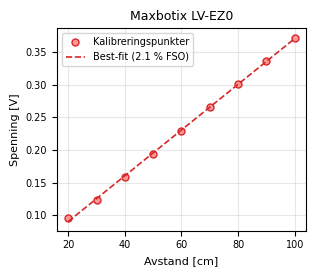

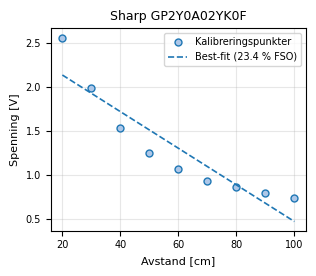

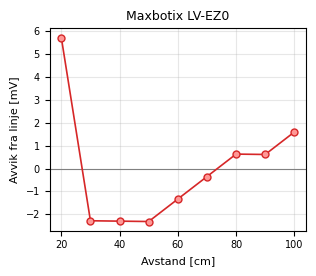

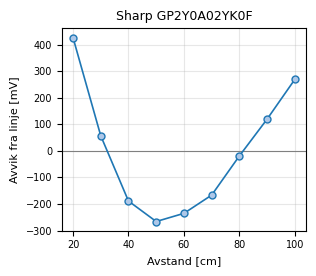

In [35]:

def les_kal(fil):
    return pd.read_csv(fil, sep=r"\s+", header=None, names=["d", "V"], decimal=",")

kal = {
    "Maxbotix LV-EZ0":    (les_kal("maxbotix_sonic_kalibreringsdata.txt"), "#d62728", "#ff9896"),
    "Sharp GP2Y0A02YK0F": (les_kal("sharp_kalibreringsdata_fra_adc.txt"),  "#1f77b4", "#aec7e8"),
}

# --- Beregninger ---
res = {}
for navn, (df, linje, punkt) in kal.items():
    d, V = df["d"].values, df["V"].values
    a, b = np.polyfit(d, V, 1)                       # best-fit rett linje V = a*d + b
    avvik = V - (a * d + b)                          # residual [V]
    fso = V.max() - V.min()                          # fullt utgangsområde [V]
    ulin = 100 * np.abs(avvik).max() / fso           # ulinearitet [% FSO]
    dx = np.linspace(d[0], d[-1], 200)
    S = PchipInterpolator(d, V).derivative()(dx) * 1000   # sensitivitet [mV/cm]
    res[navn] = dict(a=a, b=b, avvik=avvik, ulin=ulin, dx=dx, S=S)
    print(f"{navn:20s} ulinearitet = {ulin:.1f} % FSO, "
          f"|S| = {np.abs(S).min():.1f}–{np.abs(S).max():.1f} mV/cm")

KORT = {"Maxbotix LV-EZ0": "maxbotix", "Sharp GP2Y0A02YK0F": "sharp"}
LEGEND_PLASS = {"Maxbotix LV-EZ0": "upper left", "Sharp GP2Y0A02YK0F": "upper right"}

# --- 1) Transferfunksjon med best-fit linje (ulinearitet) ---
for navn, (df, linje, punkt) in kal.items():
    r = res[navn]
    d, V = df["d"].values, df["V"].values

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.plot(d, V, "o", color=punkt, markeredgecolor=linje, label="Kalibreringspunkter")
    ax.plot(d, r["a"] * d + r["b"], "--", color=linje, label=f"Best-fit ({r['ulin']:.1f} % FSO)")
    ax.set_title(navn)
    ax.set_xlabel("Avstand [cm]")
    ax.set_ylabel("Spenning [V]")
    ax.grid(alpha=0.3)
    ax.legend(loc=LEGEND_PLASS[navn])
    plt.tight_layout()
    plt.savefig(f"ulinearitet_fit_{KORT[navn]}.png", dpi=300, bbox_inches="tight")
    plt.show()

# --- 2) Avvik fra best-fit linje ---
for navn, (df, linje, punkt) in kal.items():
    r = res[navn]

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.axhline(0, color="gray", lw=0.8)
    ax.plot(df["d"], r["avvik"] * 1000, "o-", color=linje, mfc=punkt)
    ax.set_title(navn)
    ax.set_xlabel("Avstand [cm]")
    ax.set_ylabel("Avvik fra linje [mV]")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"ulinearitet_avvik_{KORT[navn]}.png", dpi=300, bbox_inches="tight")
    plt.show()

Tilpasset stigning: 3.50 mV/cm


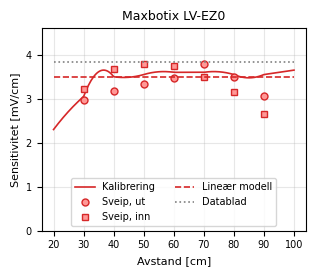

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

# --- Sveip (Maxbotix) ---
df = pd.read_csv("data/måleserie 1 ultrasonic.csv", header=None, names=["t", "V", "d"])
t, V = df.t.values, df.V.values

# Tolket referanseavstand: ca. 1 cm/s ut til 100 cm, hold ved toppen, og tilbake
ref = np.where(t <= 100, t, np.where(t <= 103, 100, 203 - t))
ut, inn = t <= 100, t >= 103

# --- Kalibrering ---
kal = pd.read_csv("maxbotix_sonic_kalibreringsdata.txt", sep=r"\s+", header=None,
                  names=["d", "V"], decimal=",")
dx = np.linspace(kal.d.min(), kal.d.max(), 200)
S_kal = PchipInterpolator(kal.d, kal.V).derivative()(dx) * 1000       # mV/cm

# Teoretisk modell: lineær tilpasning V = a*d + b  →  S = a (konstant)
a, b = np.polyfit(kal.d.values, kal.V.values, 1)
S_teori = np.full_like(dx, a * 1000)                  # mV/cm
print(f"Tilpasset stigning: {a*1000:.2f} mV/cm")

# Databladmodell: Vcc/512 per tomme (2,54 cm)
VCC = 5.0
S_ds = np.full_like(dx, VCC / 512 / 2.54 * 1000)      # ≈ 3,85 mV/cm ved 5 V


# --- Sensitivitet fra sveip: stigningstall i glidende vindu (±10 cm) ---
sentre = np.arange(30, 100, 10)
def lokal_S(maske):
    return [np.polyfit(ref[maske & (abs(ref - c) <= 10)],
                       V[maske & (abs(ref - c) <= 10)], 1)[0] * 1000 for c in sentre]
S_ut, S_inn = lokal_S(ut), lokal_S(inn)

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(dx, S_kal, "-", color="#d62728", label="Kalibrering")
ax.plot(sentre, S_ut, "o", color="#ff9896", markeredgecolor="#d62728", label="Sveip, ut")
ax.plot(sentre, S_inn, "s", color="#ff9896", markeredgecolor="#d62728", label="Sveip, inn")
ax.plot(dx, S_teori, "--", color="#d62728", label="Lineær modell")
ax.plot(dx, S_ds, ":", color="gray", label="Datablad")
ax.set_xlabel("Avstand [cm]")
ax.set_ylabel("Sensitivitet [mV/cm]")
ax.set_title("Maxbotix LV-EZ0")
ax.set_ylim(0, 4.6)
ax.grid(alpha=0.3)
ax.legend(loc="lower center", ncol=2, frameon=True)   # nedre del av plottet er tomt
plt.tight_layout()
plt.savefig("sensitivitet_maxbotix_sveip.png", dpi=300, bbox_inches="tight")
plt.show()

k = 71.4 V·cm, d0 = 8.1 cm, c = 0.049 V


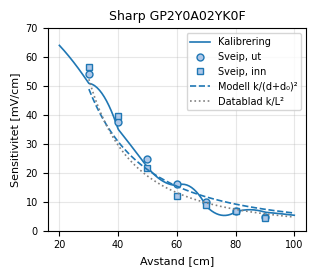

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from scipy.optimize import curve_fit
# --- Sveip (Sharp) ---
df = pd.read_csv("data/måleserie 2 sharp.csv")
t, V = df.iloc[:, 0].values, df.iloc[:, 1].values

def krysstid(maske, v):
    """Tidspunktet der V krysser v (lineær interpolasjon)."""
    i = np.where(maske)[0]; tt, vv = t[i], V[i]
    j = np.where((vv - v)[:-1] * (vv - v)[1:] <= 0)[0][0]
    return tt[j] + (v - vv[j]) * (tt[j+1] - tt[j]) / (vv[j+1] - vv[j])

ut  = (t >= 16)  & (t <= 118)      # fra dødsonen og ut til 100 cm
inn = (t >= 120) & (t <= 198)      # tilbake mot dødsonen

t20_ut, t100_ut = krysstid(ut, 2.566), 115.0     # 20 cm / 100 cm på vei ut
t100_inn, t20_inn = 122.0, krysstid(inn, 2.566)  # 100 cm / 20 cm på vei inn

ref_ut  = 20 + 80 * (t - t20_ut) / (t100_ut - t20_ut)
ref_inn = 100 - 80 * (t - t100_inn) / (t20_inn - t100_inn)

# --- Kalibrering ---
kal = pd.read_csv("sharp_kalibreringsdata_fra_adc.txt", sep=r"\s+", header=None,
                  names=["d", "V"], decimal=",")
dx = np.linspace(kal.d.min(), kal.d.max(), 200)
S_kal = np.abs(PchipInterpolator(kal.d, kal.V).derivative()(dx)) * 1000   # mV/cm

# Teoretisk modell: V = k/(d + d0) + c  →  S = |dV/dd| = k/(d + d0)^2
modell = lambda d, k, d0, c: k / (d + d0) + c
(k, d0, c), _ = curve_fit(modell, kal.d.values, kal.V.values, p0=[40, 0, 0])
S_teori = k / (dx + d0)**2 * 1000                                   # mV/cm
print(f"k = {k:.1f} V·cm, d0 = {d0:.1f} cm, c = {c:.3f} V")

# Databladmodell: V = k/L + c, fra Vo(150 cm) = 0,4 V og ΔVo(20→150 cm) = 2,05 V
k_ds = 2.05 / (1/20 - 1/150)                      # ≈ 47,3 V·cm
S_ds = k_ds / dx**2 * 1000                        # mV/cm


# --- Sensitivitet fra sveip: stigningstall i glidende vindu (±10 cm) ---
sentre = np.arange(30, 100, 10)
def lokal_S(ref, maske):
    return [abs(np.polyfit(ref[maske & (abs(ref - c) <= 10)],
                           V[maske & (abs(ref - c) <= 10)], 1)[0]) * 1000 for c in sentre]
S_ut, S_inn = lokal_S(ref_ut, ut), lokal_S(ref_inn, inn)

m = dx >= 30     # modellene gjelder bare fra ca. 30 cm

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(dx, S_kal, "-", color="#1f77b4", label="Kalibrering")
ax.plot(sentre, S_ut, "o", color="#aec7e8", markeredgecolor="#1f77b4", label="Sveip, ut")
ax.plot(sentre, S_inn, "s", color="#aec7e8", markeredgecolor="#1f77b4", label="Sveip, inn")
ax.plot(dx[m], S_teori[m], "--", color="#1f77b4", label="Modell k/(d+d₀)²")
ax.plot(dx[m], S_ds[m], ":", color="gray", label="Datablad k/L²")
ax.set_xlabel("Avstand [cm]")
ax.set_ylabel("Sensitivitet [mV/cm]")
ax.set_title("Sharp GP2Y0A02YK0F")
ax.set_ylim(0, 70)
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("sensitivitet_sharp_sveip.png", dpi=300, bbox_inches="tight")
plt.show()